# Defensive layer

Bad, tough economic times happen. This basket is designed to find the best way of managing situations. The first thing is to build a trigger which determines when bad times are either coming, or here already, and then decide what to hold when the trigger goes off.

## Imports

In [1]:
import sys
from pathlib import Path
here = Path.cwd()
src = next(c for p in [here, *here.parents]
           for c in (p / "src", p / "isa_showcase" / "src", p / "isa_portfolio" / "isa_showcase" / "src",
                     p / "trading_portfolio" / "isa_portfolio" / "isa_showcase" / "src")
           if (c / "showcase_plots.py").exists())
sys.path.insert(0, str(src))
import pandas as pd
import showcase_plots as sp
sp.style()
d = sp.monthly()

## Trigger dates

The trigger is constructed privately using general economic data. These are the times the trigger fired, and when the same trigger 'ended', or rather, when the re-entry trigger fired.

In [2]:
sp.table("trigger_spells.csv").set_index("spell")

,first_defensive_month,last_defensive_month,re_entry_month,months_defensive,open_at_window_start
spell,,,,,
1,2001-02,2002-12,2003-01,23,True
2,2008-05,2008-05,2008-06,1,False
3,2008-07,2009-07,2009-08,13,False
4,2010-07,2010-07,2010-08,1,False
5,2020-04,2020-06,2020-07,3,False


We can see that the trigger had a false re-entry in 2008, before swiftly re-entering the defensive basket. Moreover, it had a 'false-alarm' in 2010, during the Euro crisis.

## 2001-2026



Now, with the basket chosen to a collection of safe, reliable, defensive assets, I then combined the trigger, defensive basket, and the core to get the following equity curve.

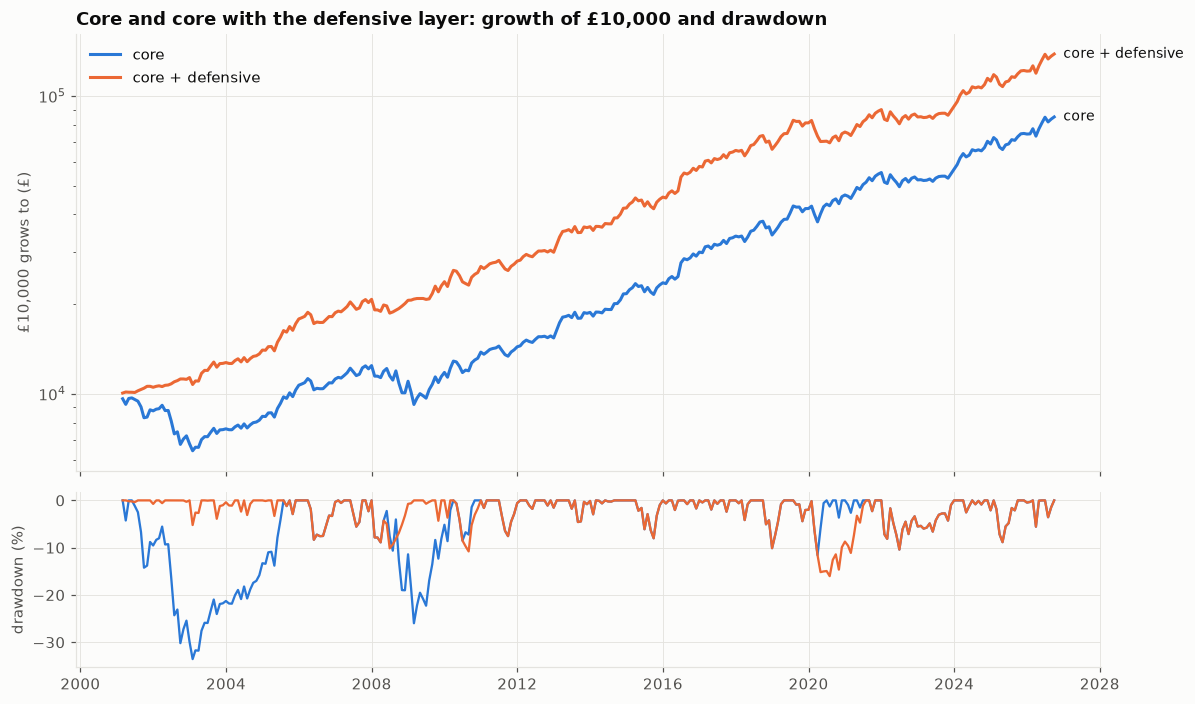

In [3]:
cd = d["core"] + d["defensive"]
sp.curves({"core": d["core"], "core + defensive": cd}, {"core": sp.COLORS["core"], "core + defensive": sp.COLORS["defensive"]}, "Core and core with the defensive layer: growth of £10,000 and drawdown")

The core+defensive basket has not only better performance over the time, but also lower drawdown everywhere apart from the later defensive entry in 2020, and the false alarm in 2010. The one area this basket is weak is the 2020 recession, due to the speed at which the market crashed, and reacted so quickly, leading the trigger to almost be reacting too slowly in both directions.

## Summary

In [4]:
sp.table("layers_stats.csv").query("layers in ['core', 'core + defensive']").set_index(["window", "layers"]).sort_index()

months  sharpe  cagr_pct  vol_pct  max_drawdown_pct  final_gbp_from_10k
window               layers                                                                                   
2001-05              core                  59  -0.160     1.334   13.329           -35.707          10,673.461
                     core + defensive      59   0.963    12.466    8.076            -5.208          17,817.717
2006-13              core                  96   0.438     7.293   13.004           -25.970          17,561.313
                     core + defensive      96   0.720     9.325   10.066           -10.787          20,406.140
2014-19              core                  72   1.330    14.319   10.115           -10.105          22,321.074
                     core + defensive      72   1.330    14.319   10.115           -10.105          22,321.074
2020-26              core                  81   0.755    11.067   11.106           -11.439          20,308.976
                     core + defensive      81   0.529     8.209   10.836           -15.888          17,032.902
book 2006-01–2026-09 core                 249   0.759    10.515   11.606           -25.970          79,608.623
                     core + defensive     249   0.827    10.377   10.336           -16.016          77,582.649
full 2001-02–2026-09 core                 308   0.560     8.694   11.997           -35.707          84,969.957
                     core + defensive     308   0.846    10.774    9.931           -16.016         138,234.566

The discussion above about the 2020 crash can be see in the stats table above, with the defensive basket underperforming the core in 2020 due to being too slow to react to both the crash, and the rebound.

## Defensive periods

Lets compared my chosen defensive basket against the core in the same period. 

In [5]:
display(sp.table("defensive_by_spell.csv").set_index("spell"))
sp.table("defensive_pooled.csv").set_index("series")

,first_defensive_month,months,core_return_pct,core_plus_defensive_return_pct,difference_pp
spell,,,,,
1,2001-02,23,-32.174,13.224,45.399
2,2008-05,1,2.132,-0.715,-2.847
3,2008-07,13,-10.107,11.657,21.763
4,2010-07,1,1.924,-1.315,-3.240
5,2020-04,3,14.726,-3.801,-18.527


,months,sharpe,cagr_pct,vol_pct,max_drawdown_pct,final_gbp_from_10k
series,,,,,,
core,41,-0.603,-8.867,18.290,-44.483,"7,281.543"
core + defensive,41,0.498,5.264,3.635,-5.626,"11,915.881"


See that the difference comes from successfully avoiding the two long recessions over the time period (2001, 2008), and the false alarms/late entries are things that count against us. The primary source of losses come from the late entry/exit in 2020 as already discussed.

## Before 2001

The trigger was originally built in-sample on 2001-2026 using macro-economic data. Lets begin by testing the trigger on the earlier data.

In [6]:
L = sp.long_parts()
sp.spells(L["defensive_on"])

,from,to,months
0,May 1979,May 1979,1
1,Apr 1980,Jun 1980,3
2,Dec 1981,Aug 1982,9
3,Feb 1990,Feb 1990,1
4,Oct 1990,Feb 1991,5
5,Dec 1991,Oct 1992,11
6,Dec 2000,Jan 2001,2


The last trigger continues through into the other period. The trigger successfully avoids both recessions from the early-1980s and early-1990s. There are also 2 false alarms in there, both lasting one month only. End with checking how this effected the book overall:

In [7]:
t = sp.period_table(L, {"core (world equity)": "core", "core + defensive": "core_defensive"})
print(f"Feb 1979 – Jan 2001, cash {t.attrs['cash']:.1f}% a year")
t.round(2)

Feb 1979 – Jan 2001, cash 10.2% a year


,CAGR %,vol %,Sharpe over cash,return / vol,max drawdown %,£10k becomes
core (world equity),14.490,18.010,0.300,0.850,-37.560,"196,099.680"
core + defensive,14.810,17.410,0.320,0.890,-37.560,"208,836.400"


See that the defensive book improved CAGR and reduced volatility slighty. The drawdown was due to a crash in 1987. The trigger is not a crash trigger, but a recession trigger, and hence it never went off in this period, so drawdown remains the same.